# Instalar mi paquete

In [ ]:
%pip install -q "git+https://github.com/adbaldel/Complex-Dynamics-Thesis.git"

In [ ]:
%pip install -q --upgrade "IPython>=9.17" "pyvista>=0.48.4"

# Dinámica de $R(z)=2z-\frac{1}{z}$

Este ejemplo contrasta con $z+1/z$: aquí infinito es atractor y el conjunto de Julia es un conjunto de Cantor contenido en el eje real. Combinaremos el análisis exacto con iteración hacia delante y hacia atrás.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
from complex_dynamics.rational_map import RationalMap

plt.style.use(
    "https://raw.githubusercontent.com/adbaldel/Complex-Dynamics-Thesis/main/code/notebooks/report.mplstyle"
)


## Puntos fijos, polos y puntos críticos

Tenemos

$$R(z)=\frac{2z^2-1}{z},\qquad R'(z)=2+\frac{1}{z^2}.$$

Los puntos fijos finitos son $\pm1$. En ambos casos el multiplicador vale $3$, así que son repulsores. Los puntos críticos finitos son $\pm i/\sqrt2$ y el único polo finito es $0$.

In [2]:
R = RationalMap([-1, 0, 2], [0, 1])
fixed_point_map = RationalMap([-1, 0, 1], [0, 1])
fixed_points = fixed_point_map.roots(include_infinity=False)
critical_points = R.derivative().roots(include_infinity=False)

print(f"R(z) = {R}")
print(f"degree = {R.degree}")
print(f"poles = {R.poles(include_infinity=False)}")
print(f"fixed points = {fixed_points}")
print(f"multipliers = {R.derivative()(fixed_points)}")
print(f"finite critical points = {critical_points}")


R(z) = \frac{2 z^{2} - 1}{z}
degree = 2
poles = [0.+0.j]
fixed points = [-1.+0.j  1.+0.j]
multipliers = [3.+0.j 3.+0.j]
finite critical points = [0.00000000e+00+0.70710678j 1.38777878e-17-0.70710678j]


## Infinito es atractor

En la coordenada local $w=1/z$,

$$G(w)=\frac{1}{R(1/w)}=\frac{w}{2-w^2}=\frac12w+O(w^3).$$

Por tanto, el multiplicador de infinito es $G'(0)=1/2$ y $\infty$ es un punto fijo atractor. Además, si $|z|>1$,

$$|R(z)|\ge 2|z|-\frac1{|z|}>|z|,$$

de modo que cruzar estrictamente la circunferencia unidad garantiza escape a infinito. La igualdad requiere cuidado porque $\pm1$ son fijos.

In [3]:
G = RationalMap([0, 1], [2, 0, -1])
sample = np.array([1.5 + 0.2j, -0.8 + 1.1j], dtype=np.complex128)

conjugacy_error = np.max(np.abs(1 / R(sample) - G(1 / sample)))
print(f"G(w) = {G}")
print(f"maximum conjugacy error = {conjugacy_error:.3e}")


G(w) = \frac{z}{2 - z^{2}}
maximum conjugacy error = 6.939e-17


## Geometría de las órbitas

Para $z=x+iy$ se cumple

$$\operatorname{Im}R(z)=y\left(2+\frac1{|z|^2}\right).$$

Todo punto no real conserva el signo de su parte imaginaria y su módulo termina creciendo hacia infinito. Sobre el eje real, la mayoría de puntos también escapa; las excepciones forman el repulsor de Cantor que constituye $J(R)$.

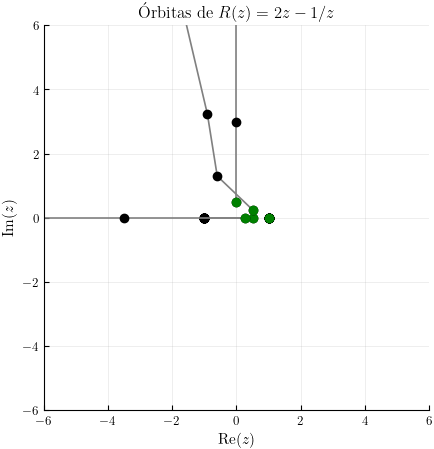

In [4]:
initial_points = np.array(
    [1, -1, 0.5, 0.25, 0.5j, 0.5 + 0.25j], dtype=np.complex128
)
max_iterations = 12
orbits = dcalc.calculate_forward_orbit(
    initial_points, R, max_iterations=max_iterations
)

fig, ax = dplot.plot_orbits(orbits)
ax.set_title(r"Órbitas de $R(z)=2z-1/z$")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect("equal")
ax.grid(True)


## Aproximación por tiempos de escape

Usamos un radio apenas mayor que $1$ porque la función del paquete considera salida cuando $|z|\ge r$. Así, cada salida detectada satisface realmente $|z|>1$ y queda matemáticamente certificada como escape. Los puntos que alcanzan el límite de iteraciones son solo candidatos a pertenecer al Julia.

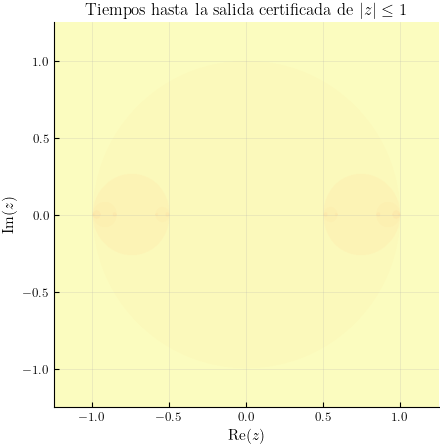

In [5]:
extent = [-1.25, 1.25, -1.25, 1.25]
mesh = dcalc.create_mesh(*extent, xpixels=700, ypixels=700)
max_iterations = 100
strict_unit_radius = np.nextafter(1.0, np.inf)
escape_times = dcalc.calculate_divergence_times(
    mesh,
    R,
    max_iterations=max_iterations,
    escape_radius=strict_unit_radius,
)

fig, ax = dplot.plot_divergence_times(
    escape_times,
    max_iterations=max_iterations,
    extent=extent,
    cmap="magma_r",
)
ax.set_title(r"Tiempos hasta la salida certificada de $|z|\leq1$")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_aspect("equal")


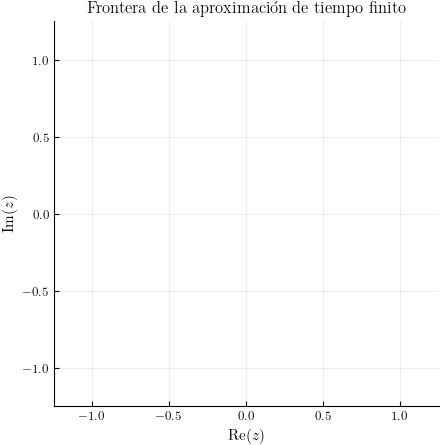

In [6]:
fig, ax = dplot.plot_divergence_times_boundary(
    escape_times,
    max_iterations=max_iterations,
    thickness=2,
    extent=extent,
)
ax.set_title("Frontera de la aproximación de tiempo finito")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_aspect("equal")


## Construcción inversa del conjunto de Julia

Resolver $R(z)=w$ equivale a resolver $2z^2-wz-1=0$, por lo que las dos ramas inversas son

$$\phi_\pm(w)=\frac{w\pm\sqrt{w^2+8}}{4}.$$

Ambas envían $[-1,1]$ dentro de los intervalos disjuntos $[-1,-1/2]$ y $[1/2,1]$. La intersección de todas las preimágenes sucesivas es un conjunto de Cantor real. Como $\pm1$ son repulsores y sus preimágenes son densas en el Julia, podemos visualizar el conjunto sin depender de un límite de escape.

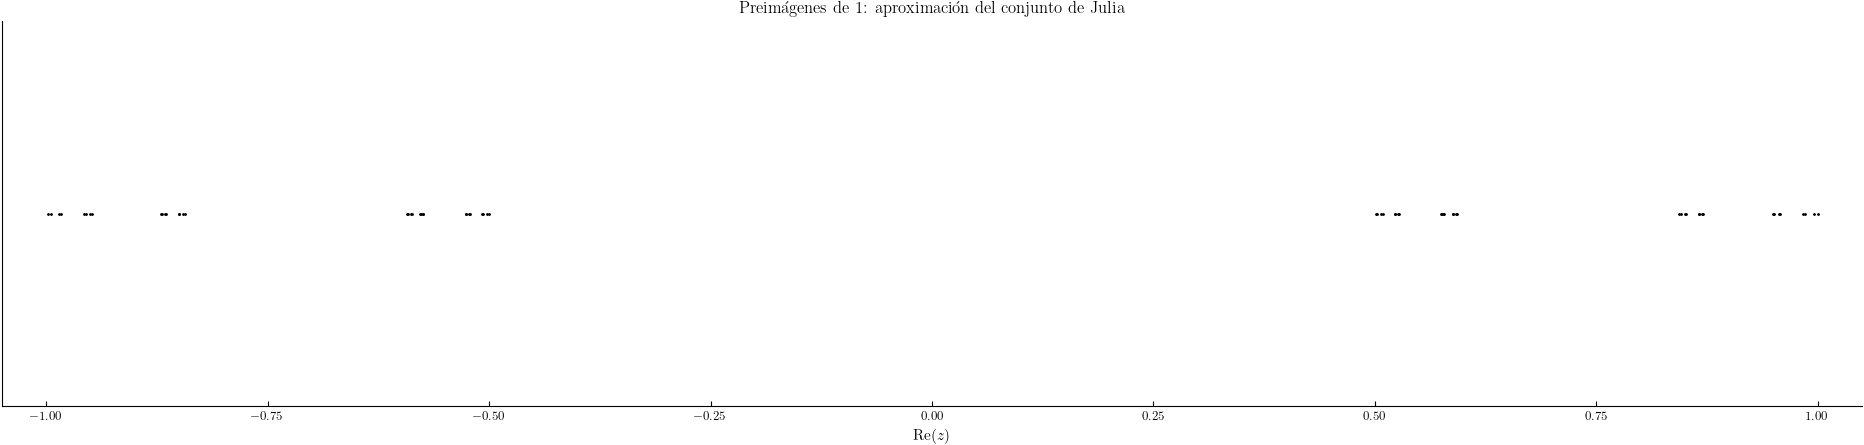

In [13]:
def inverse_branches(targets: np.ndarray) -> np.ndarray:
    values = np.asarray(targets, dtype=np.complex128)
    root = np.sqrt(values**2 + 8)
    return np.concatenate(((values + root) / 4, (values - root) / 4))


backward_points = np.array([1 + 0j])
for _ in range(6):
    backward_points = inverse_branches(backward_points)

backward_points = np.unique(np.round(backward_points.real, decimals=14))

fig, ax = plt.subplots(figsize=(24, 5))
ax.scatter(backward_points, np.zeros_like(backward_points), s=1, color="black")
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-0.08, 0.08)
ax.set_yticks([])
ax.set_title(r"Preimágenes de $1$: aproximación del conjunto de Julia")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.grid(axis="x")


## Conclusión

La esfera menos el conjunto de Cantor real pertenece a la cuenca del atractor $\infty$. Los puntos fijos $\pm1$ y todas sus preimágenes permanecen en el repulsor; cualquier punto que salga estrictamente del disco unidad escapa. La iteración inversa revela de forma especialmente clara los huecos que se abren en cada escala.